# Lab 2.1: Language Processing


In this lab, we will explore **tokenization** and **n-gram modeling** using real text data.
You will:
- Apply character, word, subword, and BPE tokenization.
- Build frequency distributions for tokens.
- Generate n-grams and compute probabilities.
- Visualize results with histograms and heatmaps.

Also, you will explore "Text Embeddings from Scratch and with Pretrained Models:

- Train **Word2Vec** embeddings on our custom dataset (`docs/`).
- Visualize the learned embeddings.
- Use pretrained embeddings with **Sentence Transformers**.
- Use a pretrained embedding model directly from **PyTorch / Hugging Face**.
- Compare the results.

The dataset is in the `docs/` directory (text files).


<table align="left">
  <td>
    <a href="https://colab.research.google.com/drive/1SdexGIpkDKmR7qclDbBQvoFqN5yb6m8E?usp=sharing" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>



# 1. Tokenization


Tokenization is the process of splitting text into smaller units. We will explore:
- Character-level tokenization
- Word-level tokenization
- Subword tokenization
- Byte-Pair Encoding (BPE)


In [31]:
# Install required packages
#!pip install torch torchvision matplotlib numpy scikit-learn nltk tokenizers

In [32]:
#!pip install gensim

In [33]:
#!pip install sentence_transformers

In [34]:
import os, re, math, random
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers, processors

%matplotlib inline
plt.rcParams["figure.figsize"] = (8,6)
random.seed(42); np.random.seed(42)


In [35]:
# -----------------------------
# Config
# -----------------------------
DOCS_DIR = "docs"              # directory containing your .txt files
MIN_FREQ = 2                   # min frequency to keep a token in vocab
K_SMOOTH = 1.0                 # add-k smoothing parameter for bi/tri
VAL_RATIO = 0.15               # validation split
TEST_RATIO = 0.10              # test split

In [36]:
# -----------------------------
# Helper functions
# -----------------------------
def load_corpus(docs_dir):
    """Load all .txt files in docs_dir into a list of strings."""
    corpus = []
    for fname in os.listdir(docs_dir):
        if fname.endswith(".txt"):
            with open(os.path.join(docs_dir, fname), "r", encoding="utf-8") as f:
                text = f.read().strip()
                corpus.append(text)
    return " ".join(corpus)


### Q1.1 - Tokenizer Implementation
Implement the following tokenizers:
- `char_tokenizer(text)`: splits text into characters.
- `word_tokenizer(text)`: splits text into words based on whitespace and punctuation.

In [37]:
# ------------------------------
# 1) Character-level
# ------------------------------
text = "Mike ate the pizza in New York City, and it was delicious!"

def char_tokenizer(text: str) -> list[str]:
    """Split text into individual characters (spaces and punctuation included)."""
    return list(text)

chars = char_tokenizer(text)
print("Character tokens:", chars)


Character tokens: ['M', 'i', 'k', 'e', ' ', 'a', 't', 'e', ' ', 't', 'h', 'e', ' ', 'p', 'i', 'z', 'z', 'a', ' ', 'i', 'n', ' ', 'N', 'e', 'w', ' ', 'Y', 'o', 'r', 'k', ' ', 'C', 'i', 't', 'y', ',', ' ', 'a', 'n', 'd', ' ', 'i', 't', ' ', 'w', 'a', 's', ' ', 'd', 'e', 'l', 'i', 'c', 'i', 'o', 'u', 's', '!']


**Expected output**:

Character tokens: ['M', 'i', 'k', 'e', ' ', 'a', 't', 'e', ' ', 't', 'h', 'e', ' ', 'p', 'i', 'z', 'z', 'a', ' ', 'i', 'n', ' ', 'N', 'e', 'w', ' ', 'Y', 'o', 'r', 'k', ' ', 'C', 'i', 't', 'y', ',', ' ', 'a', 'n', 'd', ' ', 'i', 't', ' ', 'w', 'a', 's', ' ', 'd', 'e', 'l', 'i', 'c', 'i', 'o', 'u', 's', '!']



In [38]:
# -----------------------------
# 2) Word-level
# -----------------------------
def word_tokenizer(text: str) -> list[str]:
    """Lowercase the text and keep only alphanumeric sequences (punctuation dropped)."""
    return re.findall(r"\w+", text.lower())

words = word_tokenizer(text)
print("Word tokens:", words)


Word tokens: ['mike', 'ate', 'the', 'pizza', 'in', 'new', 'york', 'city', 'and', 'it', 'was', 'delicious']


**Expected output**:

Word tokens: ['mike', 'ate', 'the', 'pizza', 'in', 'new', 'york', 'city', 'and', 'it', 'was', 'delicious']


### Visualise most common tokens:
Implement the function `def plot_token_dist(tokens)` that will plot a histogram of the top 30 tokens in frequency.
- use `count = collections.Counter(tokens)` to compute the frequency of tokens, and `char_counts.most_common(30))` to get the 30 most common
- use `plt.bar()` to plot the histogram
 

In [39]:
def plot_token_dist(tokens: list[str], top_n: int = 30, title: str = "Token distribution") -> None:
    counts = Counter(tokens)
    most_common = counts.most_common(top_n)
    labels = [repr(tok) if tok.isspace() else tok for tok, _ in most_common]
    values = [count for _, count in most_common]

    plt.figure(figsize=(12, 5))
    plt.bar(labels, values)
    plt.xticks(rotation=45, ha="right")
    plt.xlabel("Token")
    plt.ylabel("Frequency")
    plt.title(f"{title} - top {top_n} of {len(counts)} unique tokens")
    plt.tight_layout()
    plt.show()


In [40]:
# load the text from all files in the docs directory
corpus = load_corpus(DOCS_DIR)
chars = char_tokenizer(corpus)
words = word_tokenizer(corpus)

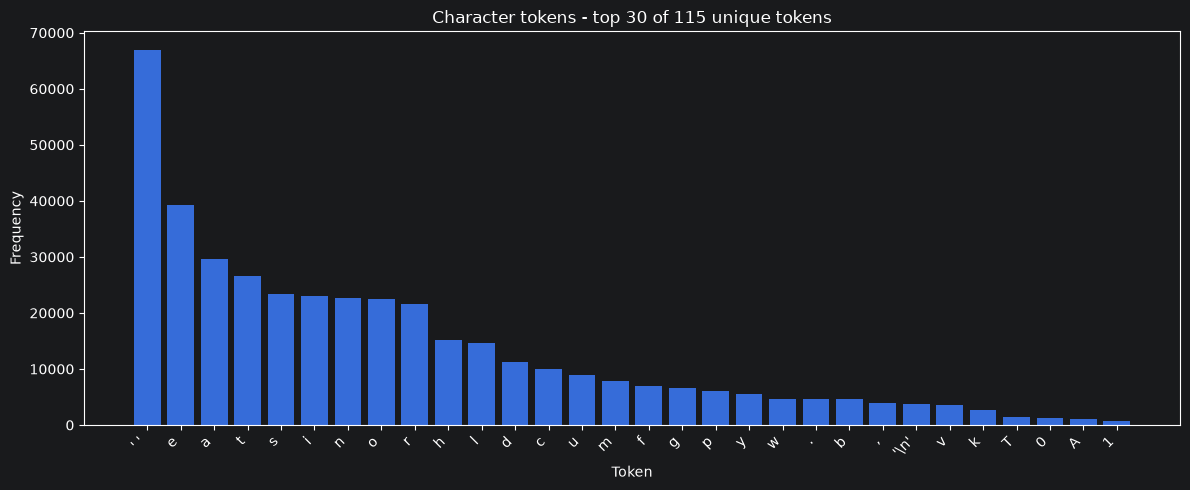

In [41]:
plot_token_dist(chars, title="Character tokens")

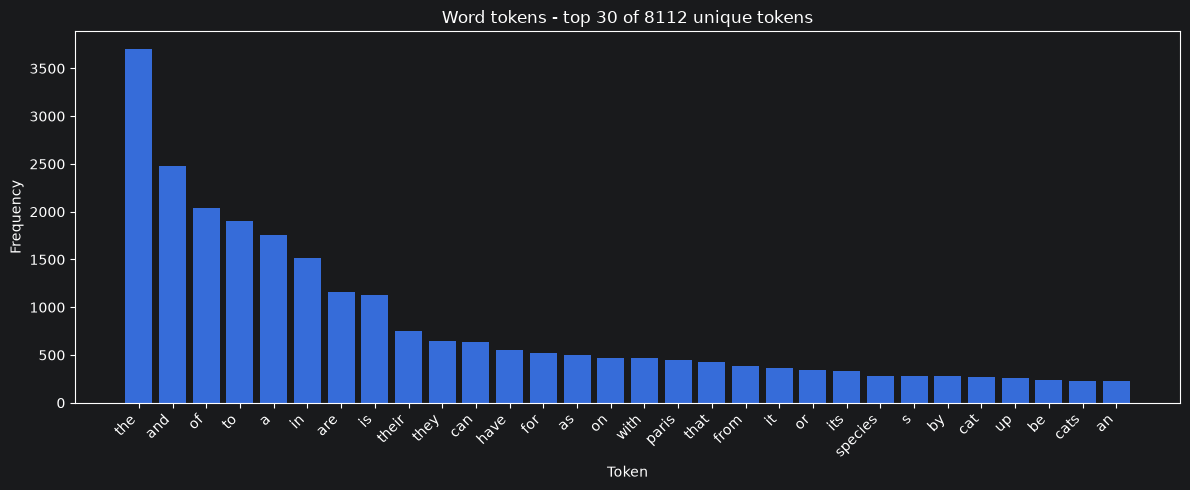

In [42]:
plot_token_dist(words, title="Word tokens")

### 1.2 Subword-level Tokenization: Byte Pair Encoding

Byte-Pair Encoding (BPE) merges frequent pairs of characters/words iteratively.  
We will use the Hugging Face `tokenizers` library.


fill the code:
- define tokenizer instance using: `Tokenizer(models.BPE())`
- define trainer `trainers.BpeTrainer(vocab_size=2000, min_frequency=2)`
- define pre-tokenizer `pre_tokenizers.Whitespace()`
- train the tokenizer on the text files in `docs/` using `tokenizer.train(files,trainer)`

In [43]:
#!pip install tokenizers

from tokenizers import Tokenizer, models, pre_tokenizers, trainers

files = [str(p) for p in Path(DOCS_DIR).glob("*.txt")]

tokenizer = Tokenizer(models.BPE())
tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
trainer = trainers.BpeTrainer(vocab_size=2000, min_frequency=2, special_tokens=["[UNK]"])
tokenizer.train(files, trainer)

print("Vocab size:", tokenizer.get_vocab_size())
print(tokenizer.encode("Mike ate the pizza in New York City, and it was delicious!").tokens)





Vocab size: 2000
['M', 'ike', 'ate', 'the', 'p', 'iz', 'z', 'a', 'in', 'New', 'Y', 'or', 'k', 'City', ',', 'and', 'it', 'was', 'de', 'l', 'ic', 'ious', '!']


# 2. N-Gram Modeling


An n-gram is a contiguous sequence of n items (characters or words).  
We will build unigram, bigram, and trigram models from our text.


### 2.1 Counting N-Grams


We generate unigrams, bigrams, and trigrams and count their frequencies.  
**Task:** Plot the most frequent bigrams and trigrams.
**Hints**
- use list(ngrams(words, n)) to compute the n-gram
- use collections.Counter to count frequencies
- use plt.bar() to plot the histogram


71574 unigrams, 71573 bigrams, 71572 trigrams
Distinct: 8112 40852 60419


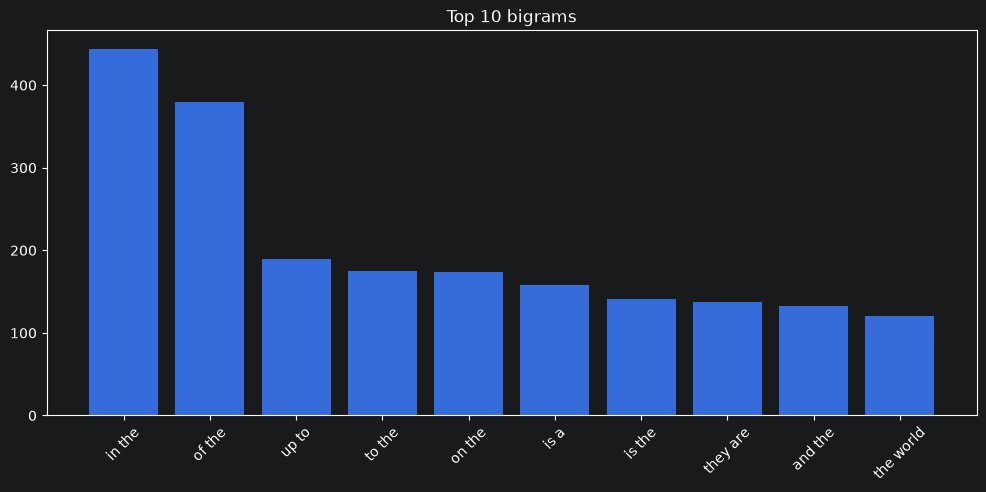

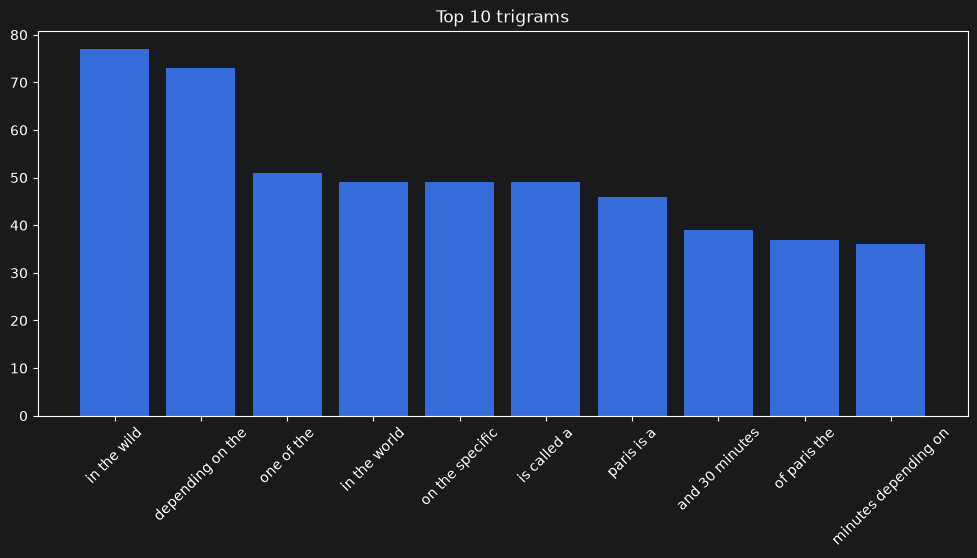

In [44]:
from nltk.util import ngrams

words = word_tokenizer(corpus)

unigrams = list(ngrams(words, 1))
bigrams = list(ngrams(words, 2))
trigrams = list(ngrams(words, 3))

word_counts = Counter(words)
unigram_counts = Counter(unigrams)
bigram_counts = Counter(bigrams)
trigram_counts = Counter(trigrams)

print(f"{len(unigrams)} unigrams, {len(bigrams)} bigrams, {len(trigrams)} trigrams")
print("Distinct:", len(unigram_counts), len(bigram_counts), len(trigram_counts))

# Plot
def plot_ngram_distribution(counts, title="N-gram Distribution"):
    plt.figure(figsize=(12,5))
    top_counts = counts.most_common(10)
    topcount_labels = [' '.join(bg) for bg, _ in top_counts]
    topcount_values = [count for _, count in top_counts]
    plt.bar(topcount_labels, topcount_values)
    plt.xticks(rotation=45)
    plt.title(title)
    plt.show()

plot_ngram_distribution(bigram_counts, title="Top 10 bigrams")
plot_ngram_distribution(trigram_counts, title="Top 10 trigrams")


### 2.2 Probability Distribution


We compute n-gram probabilities by normalizing frequencies.  
**Task:** Generate a heatmap of bigram probabilities.


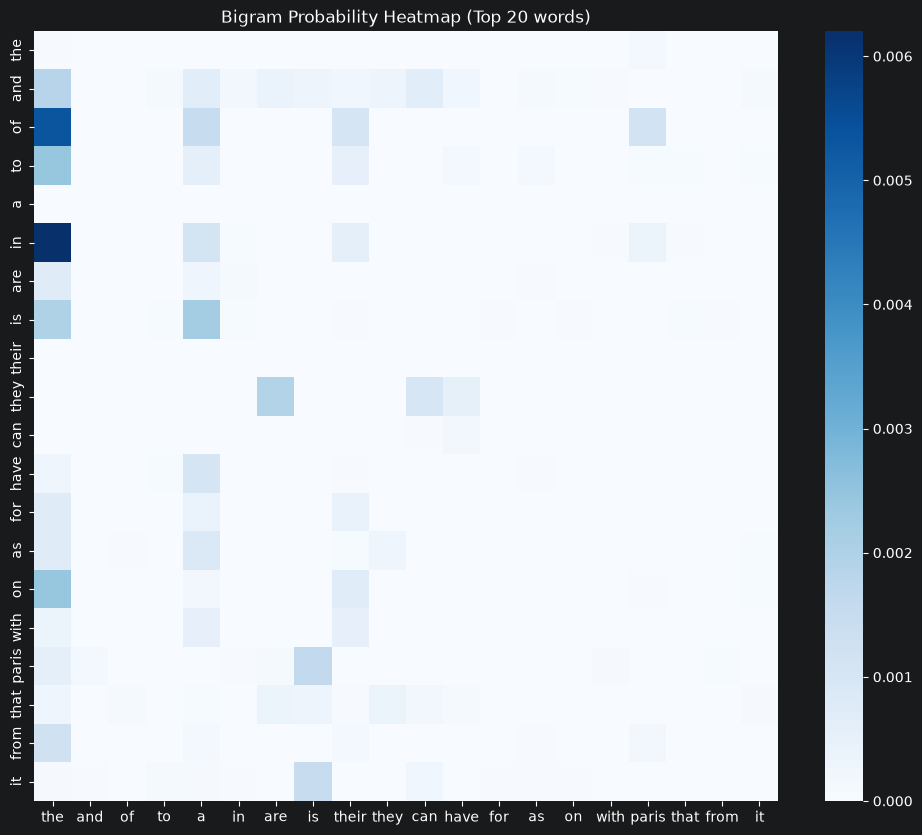

In [45]:

import numpy as np
import seaborn as sns

total_bigrams = sum(bigram_counts.values())
bigram_probs = {k: v/total_bigrams for k,v in bigram_counts.items()}

# Create heatmap for top words
top_words = [w for w,_ in word_counts.most_common(20)]
matrix = np.zeros((20,20))

for i,w1 in enumerate(top_words):
    for j,w2 in enumerate(top_words):
        if (w1,w2) in bigram_probs:
            matrix[i,j] = bigram_probs[(w1,w2)]

plt.figure(figsize=(12,10))
sns.heatmap(matrix, xticklabels=top_words, yticklabels=top_words, cmap="Blues")
plt.title("Bigram Probability Heatmap (Top 20 words)")
plt.show()


-----------

# 3 - Word Embedding

In [46]:
# 1) Install libraries:
#!pip install gensim
#!pip install -q sentence-transformers
#!pip install -q transformers torch

In [47]:
text_data = load_corpus(DOCS_DIR)

 #### 2) **Preprocess Function**:
- define `preprocess(text)` function to lowercase and tokenize text by words

In [48]:
def preprocess(text: str) -> list[str]:
    """Lowercase and split into word tokens (same rule as word_tokenizer)."""
    return re.findall(r"\w+", text.lower())

tokens = preprocess(text_data)
print("Number of tokens:", len(tokens))
print(tokens[:20])


Number of tokens: 71574
['rome', 'is', 'the', 'capital', 'city', 'of', 'italy', 'and', 'one', 'of', 'the', 'most', 'historically', 'significant', 'cities', 'in', 'the', 'world', 'often', 'called']


In [49]:
# Prepare sentences (split by '.')
sentences = [preprocess(s) for s in text_data.split(".") if len(s) > 0]
print("Number of sentences:", len(sentences))

Number of sentences: 4666


#### 3. Train a Word2Vec Model on `docs/`:
- train the model on all sentences
- vector_size=200, window=5, min_count-2, workers=4

In [50]:
from gensim.models import Word2Vec

w2v_model = Word2Vec(
    sentences,
    vector_size=200,
    window=5,
    min_count=2,
    workers=4
)

# Save model
w2v_model.save("word2vec_docs.model")

# Explore
print("Vocabulary size:", len(w2v_model.wv))
print("Most similar to 'king':", w2v_model.wv.most_similar("king", topn=5))
print("Most similar to 'paris':", w2v_model.wv.most_similar("paris", topn=5))


Vocabulary size: 4290
Most similar to 'king': [('you', 0.9969329833984375), ('due', 0.9968981742858887), ('european', 0.9968928098678589), ('making', 0.9968776106834412), ('while', 0.9968759417533875)]
Most similar to 'paris': [('a', 0.9997844099998474), ('it', 0.999719500541687), ('s', 0.9997174143791199), ('city', 0.9997129440307617), ('was', 0.9997075200080872)]


#### 4. Visualize Word Embeddings
Implement a PCA model with 3 components and apply it to the vectors of the picked words, then put the new vectors in results to be shown on the scatter

Explained variance ratio: [9.9951422e-01 1.3051141e-04 9.0108631e-05]


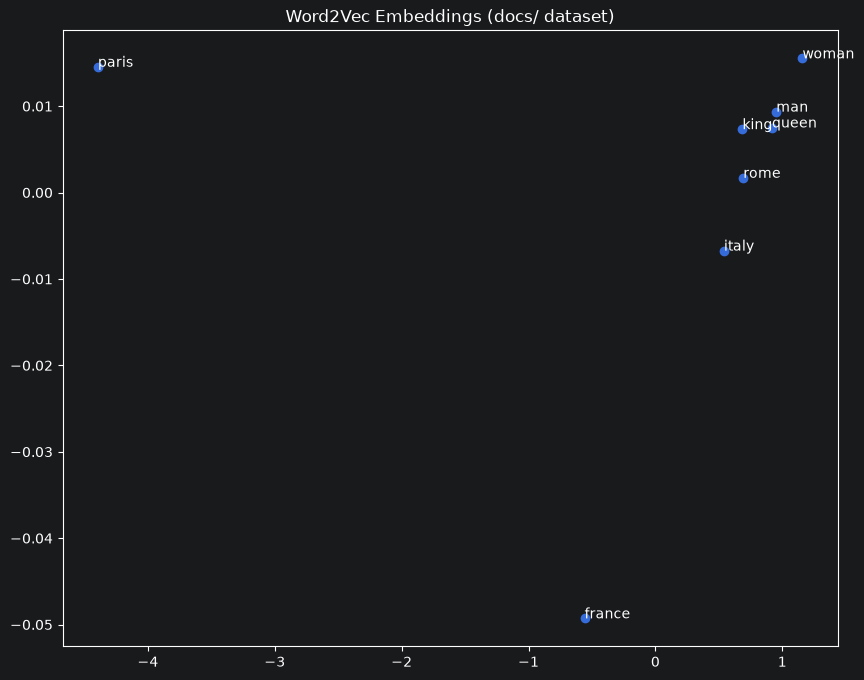

In [51]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

words = ["rome", "paris", "italy", "france", "king", "queen", "man", "woman"]
X = w2v_model.wv[words]

pca = PCA(n_components=3, random_state=42)
result = pca.fit_transform(X)
print("Explained variance ratio:", pca.explained_variance_ratio_)

plt.figure(figsize=(10,8))
plt.scatter(result[:,0], result[:,1])
for i, word in enumerate(words):
    plt.annotate(word, xy=(result[i,0], result[i,1]))
plt.title("Word2Vec Embeddings (docs/ dataset)")
plt.show()


#### 5. Use a Pretrained Embedding Model (Sentence Transformers)
- use `from sentence_transformers import SentenceTransformer`
- load the model with `model = SentenceTransformer('all-MiniLM-L6-v2')`
- compute embeddings for all sentences after splitting the text:
`model.encode(sentences)`


In [52]:
from sentence_transformers import SentenceTransformer
import re

model = SentenceTransformer("all-MiniLM-L6-v2")

# Raw (non-tokenized) sentences: encode() needs strings, not the token lists in `sentences`
sentences_docs = [s.strip() for s in re.split(r"(?<=[.!?])\s+", text_data) if len(s.strip()) > 20]

embeddings = model.encode(sentences_docs, show_progress_bar=True)
print("Number of sentences:", len(sentences_docs))
print("Embeddings shape:", embeddings.shape)


Batches: 100%|██████████| 140/140 [00:05<00:00, 23.42it/s]


Number of sentences: 4466
Embeddings shape: (4466, 384)


#### 6. Visualize Sentence Embeddings

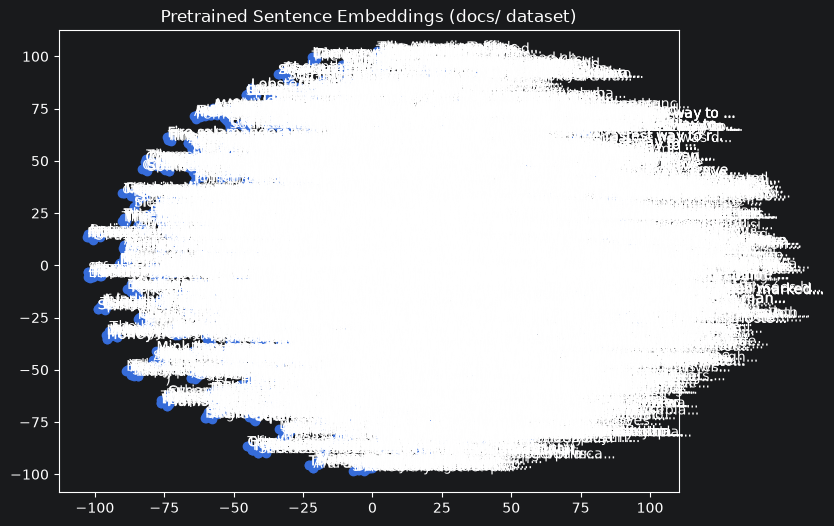

In [53]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=5)
reduced = tsne.fit_transform(embeddings)

plt.figure(figsize=(8,6))
plt.scatter(reduced[:,0], reduced[:,1])

# Annotate each point with the corresponding sentence (or first few words)
for i, sentence in enumerate(sentences_docs):
    plt.annotate(sentence[:20] + "...", (reduced[i,0], reduced[i,1])) # Annotate with truncated sentence
plt.title("Pretrained Sentence Embeddings (docs/ dataset)")
plt.show()

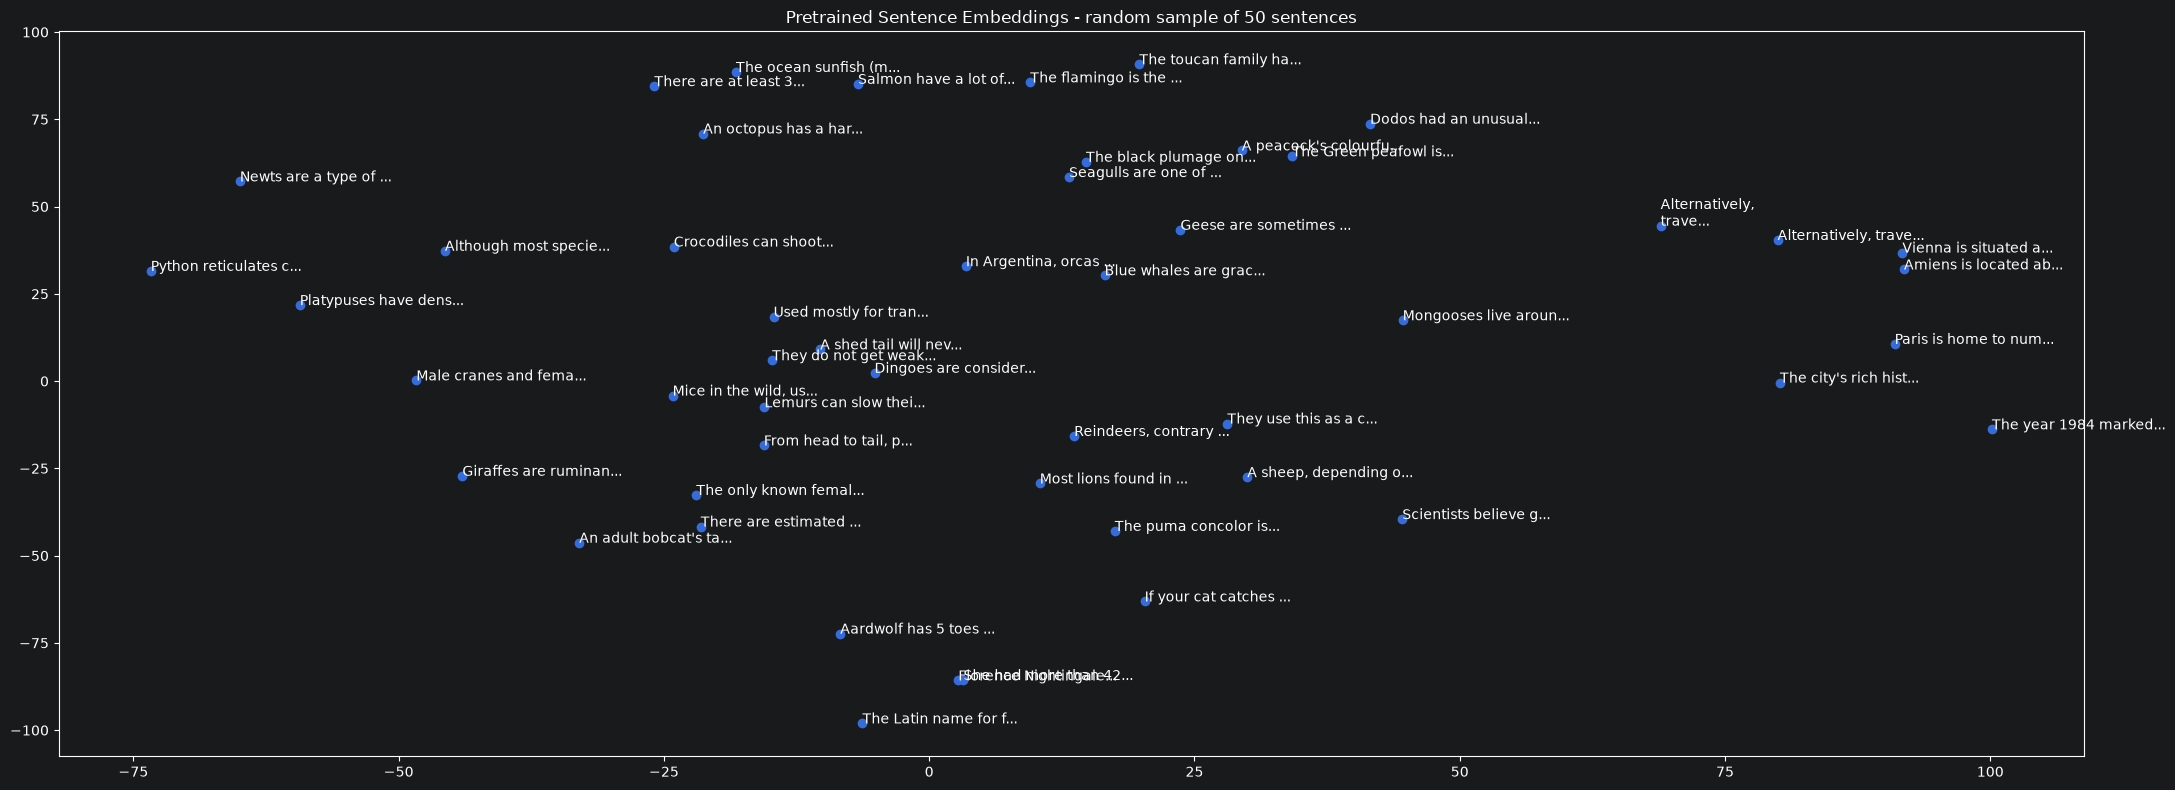

In [54]:
# Same t-SNE projection as above, but showing a random subsample so the labels stay readable
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(sentences_docs), size=50, replace=False)

plt.figure(figsize=(22, 8))
plt.scatter(reduced[sample_idx, 0], reduced[sample_idx, 1])

for i in sample_idx:
    plt.annotate(sentences_docs[i][:20] + "...", (reduced[i, 0], reduced[i, 1]))
plt.title("Pretrained Sentence Embeddings - random sample of 50 sentences")
plt.tight_layout()
plt.show()


#### 7. Use a Pretrained Embedding Model with PyTorch Transformers
- use `from transformers import AutoTokenizer, AutoModel`
- load the model and tokenizer with:
```python
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)
```
where the model to be used is : `distilbert-base-uncased"`

In [55]:
import torch
from transformers import AutoTokenizer, AutoModel
import os

# Load pretrained BERT-like model
model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)
model.eval()

# Get list of documents from docs/ directory
doc_files = [os.path.join("docs", f) for f in os.listdir("docs") if os.path.isfile(os.path.join("docs", f))]
# Generate embeddings for each document
embeddings_list = []
for doc_file in doc_files:
    with open(doc_file, "r", encoding="utf-8") as f:
        doc_text = f.read()
    inputs = tokenizer(doc_text, padding=True, truncation=True, return_tensors="pt")
    with torch.no_grad():
        outputs = model(**inputs)
        # CLS token embeddings (first token)
        embeddings_list.append(outputs.last_hidden_state[:,0,:])

# Concatenate embeddings
embeddings_torch = torch.cat(embeddings_list, dim=0)

print("Shape of embeddings:", embeddings_torch.shape)


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 5612.91it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Shape of embeddings: torch.Size([4, 768])


#### 8. Visualize Torch-based Embeddings


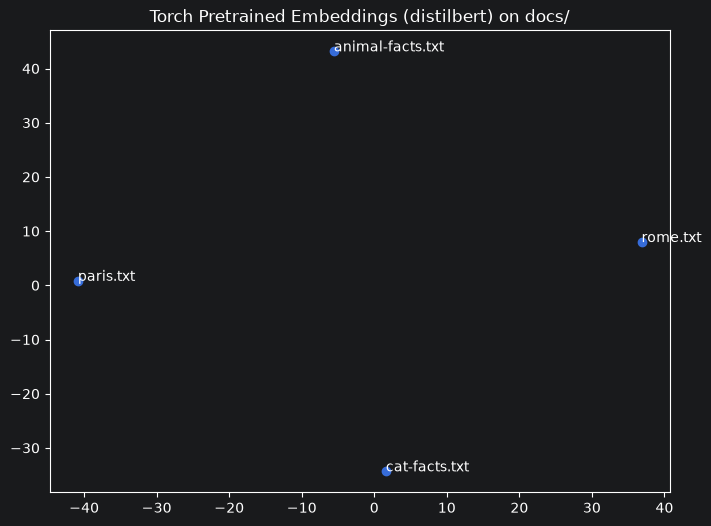

In [56]:
from sklearn.manifold import TSNE
import os

# Get list of documents from docs/ directory for annotations
doc_files = [f for f in os.listdir("docs") if os.path.isfile(os.path.join("docs", f))]


tsne = TSNE(n_components=2, random_state=42, perplexity=min(5, embeddings_torch.shape[0] - 1)) # Adjust perplexity based on number of samples
reduced_torch = tsne.fit_transform(embeddings_torch.numpy())

plt.figure(figsize=(8,6))
plt.scatter(reduced_torch[:,0], reduced_torch[:,1])

for i, doc in enumerate(doc_files):
    plt.annotate(doc, (reduced_torch[i,0], reduced_torch[i,1]))
plt.title("Torch Pretrained Embeddings (distilbert) on docs/")
plt.show()

#### 9. Wrap-Up & Discussion

- **Word2Vec**: learned *word-level embeddings* from our small dataset.
- **Sentence Transformers**: produced *document embeddings* using a large pretrained model.
- **PyTorch DistilBERT**: contextual embeddings directly from a Transformer model.

Which one gives better semantic grouping for our dataset?

Word2Vec trained on the documents doesn't work. The vocabulary is only 4 290 words, and every cosine similarity is above 0.996. The nearest neighbours of "king" are "you", "due" and "european". The model learned word frequency, not meaning. Our corpus has only 71 574 tokens, which is too small for Word2Vec.

MiniLM works much better. In the sample of 50 we can see the birds at the top center, the water animals on the left, the felines at the bottom, and the sentences about the cities alone on the right.

With DistilBERT we cannot conclude, but the problem is the setup, not the model. We encode only 4 documents, and t-SNE needs neighbours to place its points, so with 4 points it just pushes them into the four corners. This is why cat-facts ends up far from animal-facts.

The final ranking is MiniLM > DistilBERT > Word2Vec.